# Model 1 — CSP + LDA Results
**Pipeline:** CSP (6 filters, Ledoit-Wolf) → shrinkage LDA
**Band / window:** 8–30 Hz · 0.5–2.5 s post-cue
**Evaluation:** Within = LORO (3 folds) · Cross = GroupKFold-5 · Transfer = executed → imagined
**Stats:** permutation tests (Within N=200, Cross/Transfer N=1000) · BH-FDR (α=0.05)

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import os
from statsmodels.stats.multitest import multipletests
from scipy.stats import wilcoxon

# ── Paths ─────────────────────────────────────────────────────────────────
NOTEBOOK_DIR = Path(os.path.abspath("")).resolve()
RESULTS  = NOTEBOOK_DIR.parent / "modeling" / "01_csp_lda" / "results"
FIGURES  = NOTEBOOK_DIR / "figures"
FIGURES.mkdir(exist_ok=True)

# ── Load CSVs ──────────────────────────────────────────────────────────────────────
w1 = pd.read_csv(RESULTS / "model1_task1_LR_within_subject.csv")
w2 = pd.read_csv(RESULTS / "model1_task2_FF_within_subject.csv")
c1 = pd.read_csv(RESULTS / "model1_task1_LR_cross_subject.csv")            # per subject
c2 = pd.read_csv(RESULTS / "model1_task2_FF_cross_subject.csv")
cf1 = pd.read_csv(RESULTS / "model1_task1_LR_cross_subject_perfold.csv")   # per fold (5 rows)
cf2 = pd.read_csv(RESULTS / "model1_task2_FF_cross_subject_perfold.csv")
t1 = pd.read_csv(RESULTS / "model1_transfer_task1_LR.csv")
t2 = pd.read_csv(RESULTS / "model1_transfer_task2_FF.csv")

# Cross-subject significance + headline numbers both come from the pooled file (fold-mean).
c1_pooled = pd.read_csv(RESULTS / "model1_task1_LR_cross_subject_pooled.csv").iloc[0]
c2_pooled = pd.read_csv(RESULTS / "model1_task2_FF_cross_subject_pooled.csv").iloc[0]

# ── Rename accuracy columns to a common name ────────────────────────────
w1 = w1.rename(columns={"acc_loro": "acc"})
w2 = w2.rename(columns={"acc_loro": "acc"})
t1 = t1.rename(columns={"transfer_acc": "acc"})
t2 = t2.rename(columns={"transfer_acc": "acc"})

# ── BH-FDR correction ──────────────────────────────────────────────
# reject mask = first return value of multipletests
def add_fdr(df, pval_col="perm_pvalue"):
    df = df.copy()
    pvals = df[pval_col].fillna(1.0).values
    reject, _, _, _ = multipletests(pvals, method="fdr_bh")
    df["fdr_sig"] = reject.astype(int)
    return df

w1 = add_fdr(w1);  w2 = add_fdr(w2)
t1 = add_fdr(t1);  t2 = add_fdr(t2)
# Cross: per-subject FDR from cross_subject_permtest.py
SIG = pd.read_csv(NOTEBOOK_DIR / "cross_subject_persubject_significance.csv")   # from cross_subject_permtest.py

def cross_fdr(variant, task):
    return SIG[(SIG.variant == variant) & (SIG.task == task)][["subject", "fdr_sig"]]
c1 = c1.merge(cross_fdr("M1-LDA", "T1"), on="subject")
c2 = c2.merge(cross_fdr("M1-LDA", "T2"), on="subject")

# ── Experiment registry: (df, label, type, color, pooled_p, fold_df, pooled_row) ──
# Cross experiments only: pooled_p, fold_df, pooled_row (else None).
EXPS = [
    (w1, "Within T1  (L/R fist)",     "Within",   "#3b6fd4", None, None, None),
    (w2, "Within T2  (Fists/Feet)",   "Within",   "#3b6fd4", None, None, None),
    (c1, "Cross T1   (L/R fist)",     "Cross",    "#2d7a3a", float(c1_pooled["perm_pvalue"]), cf1, c1_pooled),
    (c2, "Cross T2   (Fists/Feet)",   "Cross",    "#2d7a3a", float(c2_pooled["perm_pvalue"]), cf2, c2_pooled),
    (t1, "Transfer T1 (L/R fist)",    "Transfer", "#b45309", None, None, None),
    (t2, "Transfer T2 (Fists/Feet)",  "Transfer", "#b45309", None, None, None),
]

# ── Summary table ─────────────────────────────────────────────────────────
rows = []
for df, label, etype, _, pooled_p, _, pooled_row in EXPS:
    if pooled_row is not None:
        acc, bal_acc, auc, kappa = pooled_row["acc"], pooled_row["bal_acc"], pooled_row["auc"], pooled_row["kappa"]
        sens, spec = pooled_row["sensitivity"], pooled_row["specificity"]
    else:
        acc, bal_acc, auc, kappa = df["acc"].mean(), df["bal_acc"].mean(), df["auc"].mean(), df["kappa"].mean()
        sens, spec = df["sensitivity"].mean(), df["specificity"].mean()
    if pooled_p is None:
        _, group_p = wilcoxon(df["acc"] - 0.5)
    else:
        group_p = pooled_p
    fdr = f"{int(df['fdr_sig'].sum())}/106"
    rows.append({
        "Experiment":  label,
        "Type":        etype,
        "Acc":         round(acc, 3),
        "Bal.Acc":     round(bal_acc, 3),
        "AUC":         round(auc, 3),
        "Kappa":       round(kappa, 3),
        "Sensitivity": round(sens, 3),
        "Specificity": round(spec, 3),
        "Group p":     f"{group_p:.2g}",
        "FDR sig":     fdr,
    })

summary = pd.DataFrame(rows).set_index("Experiment")
print("=" * 80)
print("Model 1 (CSP + LDA) -- Summary Statistics")
print("(Within/Transfer: mean across 106 subjects · Cross: mean across 5 GroupKFold folds)")
print("(Group p: Wilcoxon vs 0.5 for Within/Transfer · pooled permutation test for Cross)")
print("=" * 80)
display(summary)

Model 1 (CSP + LDA) -- Summary Statistics
(Within/Transfer: mean across 106 subjects · Cross: mean across 5 GroupKFold folds)
(Group p: Wilcoxon vs 0.5 for Within/Transfer · pooled permutation test for Cross)


,Type,Acc,Bal.Acc,AUC,Kappa,Sensitivity,Specificity,Group p,FDR sig
Experiment,,,,,,,,,
Within T1 (L/R fist),Within,0.583,0.583,0.616,0.165,0.616,0.549,1.7e-11,22/106
Within T2 (Fists/Feet),Within,0.643,0.644,0.692,0.287,0.646,0.642,1.1e-14,39/106
Cross T1 (L/R fist),Cross,0.611,0.611,0.664,0.222,0.602,0.620,0.001,30/106
Cross T2 (Fists/Feet),Cross,0.614,0.614,0.664,0.228,0.600,0.629,0.001,32/106
Transfer T1 (L/R fist),Transfer,0.572,0.574,0.617,0.147,0.644,0.503,1.7e-08,15/106
Transfer T2 (Fists/Feet),Transfer,0.624,0.624,0.704,0.248,0.626,0.622,6.6e-14,38/106


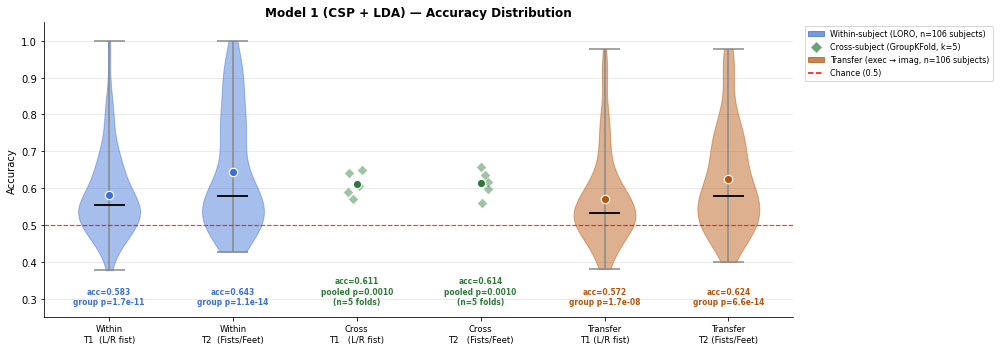

Saved model1_accuracy_violin.png


In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(14, 5))
positions = np.arange(1, 7)

# Cross-subject (5 folds): jittered points. Within/Transfer (n=106): violins.
violin_positions, violin_data, violin_colors = [], [], []
strip_positions, strip_data, strip_colors = [], [], []
for pos, (df, label, etype, color, pooled_p, fold_df, pooled_row) in zip(positions, EXPS):
    if fold_df is not None:
        strip_positions.append(pos); strip_data.append(fold_df["acc"].values); strip_colors.append(color)
    else:
        violin_positions.append(pos); violin_data.append(df["acc"].values); violin_colors.append(color)

parts = ax.violinplot(violin_data, positions=violin_positions, showmedians=True, showextrema=True)
for pc, color in zip(parts["bodies"], violin_colors):
    pc.set_facecolor(color); pc.set_alpha(0.45); pc.set_edgecolor(color)
parts["cmedians"].set_color("#111"); parts["cmedians"].set_linewidth(2)
for key in ("cmaxes", "cmins", "cbars"):
    parts[key].set_color("#888")

rng = np.random.default_rng(0)
for pos, vals, color in zip(strip_positions, strip_data, strip_colors):
    jitter = rng.uniform(-0.07, 0.07, size=len(vals))
    ax.scatter(np.full(len(vals), pos) + jitter, vals, color=color, alpha=0.45, s=50,
               marker="D", edgecolors="white", linewidth=0.7, zorder=3)

for i, (df, label, etype, color, pooled_p, fold_df, pooled_row) in enumerate(EXPS):
    mean_val = pooled_row["acc"] if pooled_row is not None else df["acc"].mean()
    ax.scatter(positions[i], mean_val, color=color, s=70, zorder=5,
               edgecolors="white", linewidth=1.2)
    if pooled_p is None:
        # group-level: one-sample Wilcoxon vs chance
        _, group_p = wilcoxon(df["acc"] - 0.5)
        sig_txt = f"group p={group_p:.2g}"
    else:
        sig_txt = f"pooled p={pooled_p:.4f}\n(n=5 folds)"
    ax.text(positions[i], 0.28, f"acc={mean_val:.3f}\n{sig_txt}",
            ha="center", va="bottom", fontsize=7.5, color=color, fontweight="bold")

ax.axhline(0.5, color="red", linestyle="--", linewidth=1.2, alpha=0.75)
ax.set_xticks(positions)
ax.set_xticklabels([d[1].replace(" ", "\n", 1) for d in EXPS], fontsize=8.5)
ax.set_ylabel("Accuracy", fontsize=10)
ax.set_ylim(0.25, 1.05)
ax.set_title("Model 1 (CSP + LDA) — Accuracy Distribution", fontsize=12, fontweight="bold")
ax.yaxis.grid(True, alpha=0.3); ax.set_axisbelow(True)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
legend_handles = [
    mpatches.Patch(color="#3b6fd4", alpha=0.7, label="Within-subject (LORO, n=106 subjects)"),
    plt.Line2D([0], [0], marker="D", color="w", markerfacecolor="#2d7a3a", markersize=8, alpha=0.7,
               label="Cross-subject (GroupKFold, k=5)"),
    mpatches.Patch(color="#b45309", alpha=0.7, label="Transfer (exec → imag, n=106 subjects)"),
    plt.Line2D([0], [0], color="red", linestyle="--", label="Chance (0.5)"),
]
ax.legend(handles=legend_handles, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=True)
plt.tight_layout()
plt.savefig(FIGURES / "model1_accuracy_violin.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved model1_accuracy_violin.png")

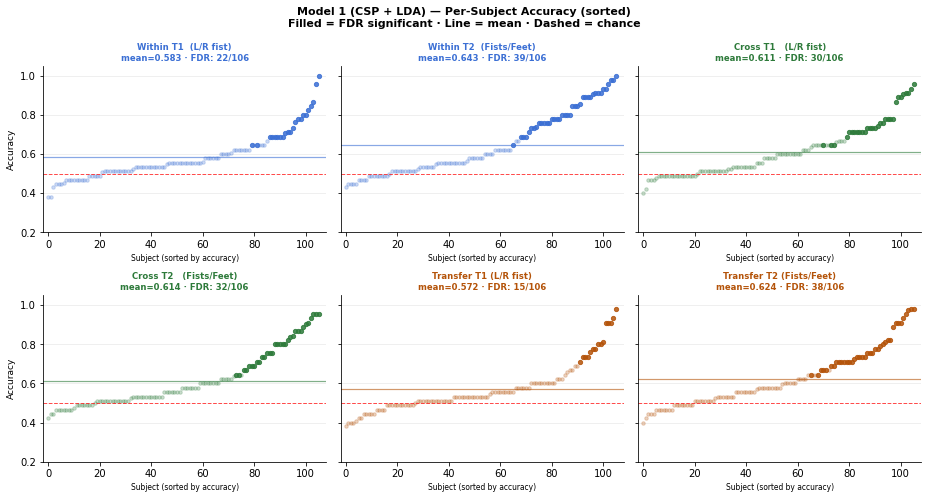

Saved model1_accuracy_dotplot.png


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
axes = axes.flatten()

for ax, (df, label, etype, color, pooled_p, fold_df, pooled_row) in zip(axes, EXPS):
    vals = df["acc"].values
    order  = np.argsort(vals)
    vals_s = vals[order]
    x = np.arange(len(vals_s))
    sig = df["fdr_sig"].values.astype(int)
    sig_s = sig[order]
    ax.scatter(x[sig_s == 0], vals_s[sig_s == 0], color=color, alpha=0.25, s=12)
    ax.scatter(x[sig_s == 1], vals_s[sig_s == 1], color=color, alpha=0.85, s=18, label="FDR sig.")
    title_sig = f"FDR: {int(sig.sum())}/106"
    ax.axhline(0.5,          color="red",   linestyle="--", linewidth=1, alpha=0.7)
    ax.axhline(vals.mean(),  color=color,   linestyle="-",  linewidth=1.2, alpha=0.6)
    ax.set_title(f"{label}\nmean={vals.mean():.3f} · {title_sig}",
                 fontsize=8.5, fontweight="bold", color=color)
    ax.set_xlabel("Subject (sorted by accuracy)", fontsize=7.5)
    ax.set_xlim(-2, 108); ax.set_ylim(0.2, 1.05)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, alpha=0.25); ax.set_axisbelow(True)

axes[0].set_ylabel("Accuracy", fontsize=9)
axes[3].set_ylabel("Accuracy", fontsize=9)
fig.suptitle("Model 1 (CSP + LDA) — Per-Subject Accuracy (sorted)\n"
             "Filled = FDR significant · Line = mean · Dashed = chance",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "model1_accuracy_dotplot.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved model1_accuracy_dotplot.png")

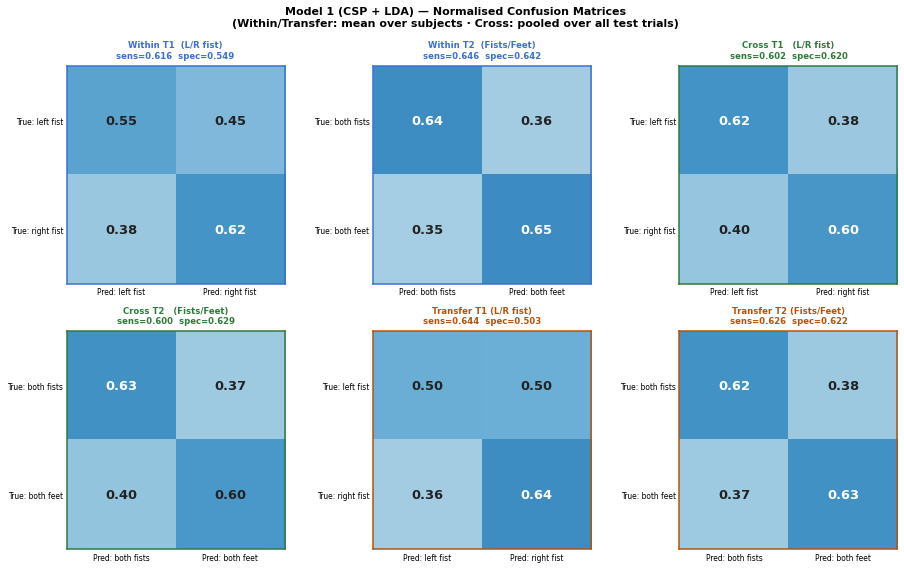

Saved model1_confusion_matrices.png


In [4]:
CLASS_LABELS = [
    ("left fist", "right fist"),
    ("both fists", "both feet"),
    ("left fist", "right fist"),
    ("both fists", "both feet"),
    ("left fist", "right fist"),
    ("both fists", "both feet"),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()
for ax, (df, label, etype, color, pooled_p, fold_df, pooled_row), (cls0, cls1) in zip(axes, EXPS, CLASS_LABELS):
    src  = pooled_row if pooled_row is not None else df[["sensitivity", "specificity"]].mean()
    sens = src["sensitivity"]
    spec = src["specificity"]
    # Rows = actual class, Cols = predicted class (normalised rates)
    cm = np.array([
        [spec,       1 - spec],
        [1 - sens,   sens    ],
    ])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for r in range(2):
        for c in range(2):
            txt_color = "white" if cm[r, c] > 0.6 else "#222"
            ax.text(c, r, f"{cm[r, c]:.2f}", ha="center", va="center",
                    fontsize=13, fontweight="bold", color=txt_color)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels([f"Pred: {cls0}", f"Pred: {cls1}"], fontsize=7.5)
    ax.set_yticklabels([f"True: {cls0}", f"True: {cls1}"], fontsize=7.5)
    ax.set_title(f"{label}\nsens={sens:.3f}  spec={spec:.3f}",
                 fontsize=8.5, fontweight="bold", color=color, pad=8)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_edgecolor(color); spine.set_linewidth(1.5)

fig.suptitle("Model 1 (CSP + LDA) — Normalised Confusion Matrices\n"
             "(Within/Transfer: mean over subjects · Cross: pooled over all test trials)",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "model1_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved model1_confusion_matrices.png")
